# Real-Time Facial Emotion Recognition

## 0. Install & imports

In [ ]:
# Run once if needed:
# !pip install tensorflow numpy matplotlib seaborn scikit-learn
# !pip install "opencv-python==4.11.0.86"

In [11]:
import os, time, collections
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__, "| OpenCV:", cv2.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | OpenCV: 4.11.0
GPUs: []


## 1. Configuration

In [14]:
DATA_DIR   = "fer2013"          # folder containing train/ and test/
IMG_SIZE   = (48, 48)
BATCH_SIZE = 64
EPOCHS     = 10
MODEL_PATH = "emotion_cnn.keras"
SEED       = 42

tf.keras.utils.set_random_seed(SEED)

## 2. Load the dataset

In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True, seed=SEED,
)
test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False,
)

class_names = train_ds.class_names      # alphabetical order
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.prefetch(tf.data.AUTOTUNE)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### Peek at the data and class balance

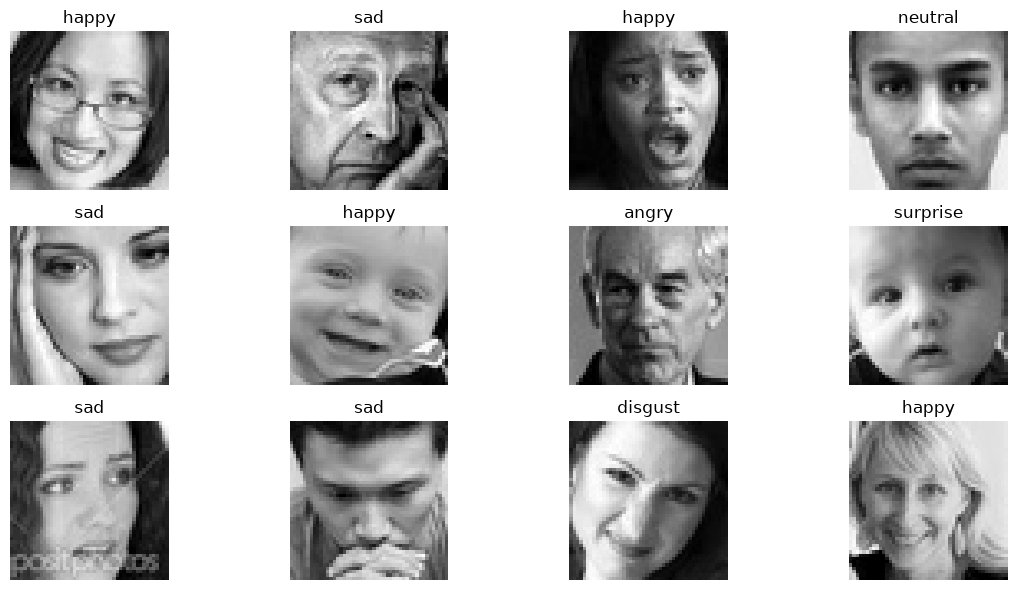

In [11]:
plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")
plt.tight_layout(); plt.show()

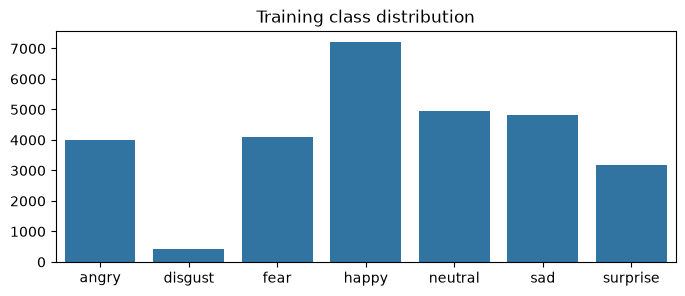

Class weights: {'angry': np.float64(1.03), 'disgust': np.float64(9.41), 'fear': np.float64(1.0), 'happy': np.float64(0.57), 'neutral': np.float64(0.83), 'sad': np.float64(0.85), 'surprise': np.float64(1.29)}


In [12]:
# Class distribution (FER2013 is imbalanced: 'disgust' is tiny)
y_train = np.concatenate([np.argmax(y, axis=1) for _, y in train_ds])
counts = np.bincount(y_train, minlength=NUM_CLASSES)
plt.figure(figsize=(8, 3))
sns.barplot(x=class_names, y=counts)
plt.title("Training class distribution"); plt.show()

weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))
print("Class weights:", {class_names[k]: round(v, 2) for k, v in class_weight.items()})

## 3. Build the CNN

In [13]:
def conv_block(x, filters, dropout):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(dropout)(x)

def build_model(input_shape=(48, 48, 1), num_classes=7):
    inp = layers.Input(shape=input_shape)

    # Preprocessing + augmentation (augmentation only active during training)
    x = layers.Rescaling(1.0 / 255)(inp)
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)

    x = conv_block(x, 32, 0.25)
    x = conv_block(x, 64, 0.25)
    x = conv_block(x, 128, 0.30)
    x = conv_block(x, 256, 0.35)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inp, out, name="emotion_cnn")

model = build_model((*IMG_SIZE, 1), NUM_CLASSES)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 48, 48, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12, 12, 64)     │             

 Total params: 1,243,175 (4.74 MB)

 Trainable params: 1,240,743 (4.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

## 4. Train

In [15]:
cbs = [
    callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_accuracy", patience=12, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=cbs,
)

Epoch 1/10


e:\Deep Learning Projects\Facial Emotion Recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.1529 - loss: 2.2513
Epoch 1: val_accuracy improved from None to 0.19978, saving model to emotion_cnn.keras

Epoch 1: finished saving model to emotion_cnn.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 254s 551ms/step - accuracy: 0.1529 - loss: 2.2513 - val_accuracy: 0.1998 - val_loss: 1.9146 - learning_rate: 0.0010
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.1603 - loss: 2.0253
Epoch 2: val_accuracy did not improve from 0.19978
449/449 ━━━━━━━━━━━━━━━━━━━━ 254s 566ms/step - accuracy: 0.1603 - loss: 2.0253 - val_accuracy: 0.1994 - val_loss: 1.8939 - learning_rate: 0.0010
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 531ms/step - accuracy: 0.1714 - loss: 1.9597
Epoch 3: val_accuracy improved from 0.19978 to 0.26846, saving model to emotion_cnn.keras

Epoch 3: finished saving model to emotion_cnn.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 251s 559ms/step - accuracy: 0.1714 - loss: 1.9597 - val_accuracy: 0.2685 - val_loss: 1.7956 - 